<a href="https://colab.research.google.com/github/emanfalak53-creator/Natural-Language-Processing-/blob/main/LAB_7_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import spacy
from spacy import displacy

nlp = spacy.load("en_core_web_sm")

text = "Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to invest 500 million dollars across Asia by 2025."

doc = nlp(text)

html = displacy.render(doc, style="ent", page=True, jupyter=False)
with open("entities.html", "w", encoding="utf-8") as f:
    f.write(html)

options = {"ents": ["ORG", "GPE"]}
html = displacy.render(doc, style="ent", options=options, page=True, jupyter=False)
with open("entities_filtered.html", "w", encoding="utf-8") as f:
    f.write(html)

colors = {"ORG": "orange", "GPE": "lightgreen"}
options = {"ents": ["ORG", "GPE"], "colors": colors}
html = displacy.render(doc, style="ent", options=options, page=True, jupyter=False)
with open("entities_colored.html", "w", encoding="utf-8") as f:
    f.write(html)

first_sentence = list(doc.sents)[0]
html = displacy.render(first_sentence, style="dep", page=True, jupyter=False)
with open("dependency.html", "w", encoding="utf-8") as f:
    f.write(html)

print("HTML files saved successfully!")

HTML files saved successfully!


{'PRON': 5, 'VERB': 4, 'NOUN': 3, 'PUNCT': 3, 'ADV': 3, 'ADJ': 2, 'PROPN': 1, 'NUM': 1, 'CCONJ': 1, 'ADP': 1, 'DET': 1}
{'VBD': 4, '.': 3, 'PRP': 3, 'RB': 3, 'JJ': 2, 'NNS': 2, 'NN': 2, 'NNP': 1, 'CD': 1, 'CC': 1, 'IN': 1, 'PRP$': 1, 'DT': 1}


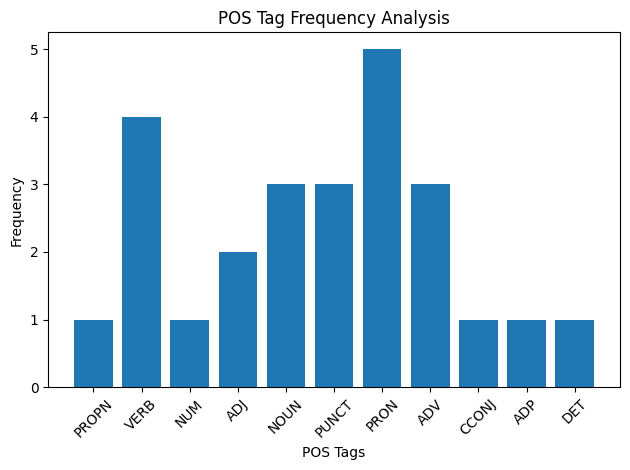

In [13]:
import spacy
from collections import Counter
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")

text = "Ali bought three fresh apples. He carefully washed them and quickly shared them with his friends. Everyone happily enjoyed the sweet fruit."
doc = nlp(text)

pos_counts = Counter(token.pos_ for token in doc)
fine_counts = Counter(token.tag_ for token in doc)

print(dict(pos_counts.most_common()))
print(dict(fine_counts.most_common()))

plt.bar(pos_counts.keys(), pos_counts.values())
plt.xlabel("POS Tags")
plt.ylabel("Frequency")
plt.title("POS Tag Frequency Analysis")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
import spacy

nlp = spacy.load("en_core_web_sm")

sentences = [
    "I will book a flight to Lahore.",
    "She read a good book yesterday.",
    "They run every morning.",
    "We watched the run of the play."
]

for sentence in sentences:
    doc = nlp(sentence)
    for token in doc:
        if token.text.lower() in ("book", "run"):
            print(sentence, token.text, token.pos_, token.tag_)

def compare_word(word, sentences):
    results = []
    for i, sentence in enumerate(sentences, start=1):
        doc = nlp(sentence)
        for token in doc:
            if token.text.lower() == word.lower():
                results.append((i, token.pos_, token.tag_))
    return results

print(compare_word("book", sentences))
print(compare_word("run", sentences))

extra_sentences = [
    "I watch television every night.",
    "My watch is expensive.",
    "Turn on the light.",
    "This bag is light."
]

print(compare_word("watch", extra_sentences))
print(compare_word("light", extra_sentences))

I will book a flight to Lahore. book VERB VB
She read a good book yesterday. book NOUN NN
They run every morning. run VERB VBP
We watched the run of the play. run NOUN NN
[(1, 'VERB', 'VB'), (2, 'NOUN', 'NN')]
[(3, 'VERB', 'VBP'), (4, 'NOUN', 'NN')]
[(1, 'VERB', 'VBP'), (2, 'NOUN', 'NN')]
[(3, 'NOUN', 'NN'), (4, 'ADJ', 'JJ')]


In [15]:
import spacy

nlp = spacy.load("en_core_web_sm")

text = " Hello!!! The price is $45.50 ... (really?)\n\n Is it worth it? xyz123 @@ "

doc = nlp(text)

for token in doc:
    print(token.text, token.pos_)

cleaned = [token for token in doc if token.pos_ not in ("SPACE", "PUNCT", "X")]

removed = len(doc) - len(cleaned)
percentage = (removed / len(doc)) * 100

print("\nCleaned tokens:")
print([token.text for token in cleaned])

print("Removed tokens:", removed)
print("Percentage removed:", round(percentage, 2), "%")

def clean_pos(text, remove=("SPACE", "PUNCT", "X")):
    doc = nlp(text)
    return [(token.text, token.pos_) for token in doc if token.pos_ not in remove]

text2 = "Wow!!! I bought 123 items... @@@ this is amazing!!!"

print("\nCleaned second text:")
print(clean_pos(text2))

  SPACE
Hello INTJ
! PUNCT
! PUNCT
! PUNCT
The DET
price NOUN
is AUX
$ SYM
45.50 NUM
... PUNCT
( PUNCT
really ADV
? PUNCT
) PUNCT


  SPACE
Is AUX
it PRON
worth ADJ
it PRON
? PUNCT
xyz123 PROPN
@@ PROPN

Cleaned tokens:
['Hello', 'The', 'price', 'is', '$', '45.50', 'really', 'Is', 'it', 'worth', 'it', 'xyz123', '@@']
Removed tokens: 10
Percentage removed: 43.48 %

Cleaned second text:
[('Wow', 'INTJ'), ('I', 'PRON'), ('bought', 'VERB'), ('123', 'NUM'), ('items', 'NOUN'), ('@@@', 'PROPN'), ('this', 'PRON'), ('is', 'AUX'), ('amazing', 'ADJ')]


In [16]:
import spacy

nlp = spacy.load("en_core_web_sm")

text = "Fatima quickly opened the old wooden door and slowly walked into the dark room. She carefully placed a small lamp on the heavy table."

doc = nlp(text)

nouns = [token.text for token in doc if token.pos_ in ("NOUN", "PROPN")]
print("Nouns:", nouns)

verbs = [(token.text, token.lemma_) for token in doc if token.pos_ == "VERB"]
print("Verbs and Lemmas:", verbs)

pairs = [doc[i].text + " " + doc[i+1].text for i in range(len(doc)-1) if doc[i].pos_ == "ADJ" and doc[i+1].pos_ == "NOUN"]
print("Adjective-Noun pairs:", pairs)

noun_count = len(nouns)
verb_count = len([token for token in doc if token.pos_ == "VERB"])
adjective_count = len([token for token in doc if token.pos_ == "ADJ"])
adverb_count = len([token for token in doc if token.pos_ == "ADV"])

print("\nSummary")
print("Nouns:", noun_count)
print("Verbs:", verb_count)
print("Adjectives:", adjective_count)
print("Adverbs:", adverb_count)

Nouns: ['Fatima', 'door', 'room', 'lamp', 'table']
Verbs and Lemmas: [('opened', 'open'), ('walked', 'walk'), ('placed', 'place')]
Adjective-Noun pairs: ['wooden door', 'dark room', 'small lamp', 'heavy table']

Summary
Nouns: 5
Verbs: 3
Adjectives: 5
Adverbs: 3


In [17]:
import spacy

nlp = spacy.load("en_core_web_sm")

text = "Imran Khan visited Google headquarters in California on March 3, 2019, and discussed a $2 million investment for Pakistan. Later, Microsoft and Amazon announced new offices in Lahore."

doc = nlp(text)

for ent in doc.ents:
    print(ent.text, ent.label_, ent.start_char, ent.end_char)

print("\nEntity Explanations:")
labels = set(ent.label_ for ent in doc.ents)

for label in labels:
    print(label, ":", spacy.explain(label))

grouped = {}

for ent in doc.ents:
    grouped.setdefault(ent.label_, []).append(ent.text)

print("\nEntities Grouped by Label:")
print(grouped)

counts = {}

for ent in doc.ents:
    counts[ent.label_] = counts.get(ent.label_, 0) + 1

print("\nEntity Counts:")
print(counts)

if counts:
    print("Most frequent entity type:", max(counts, key=counts.get))

Khan PERSON 6 10
Google ORG 19 25
California GPE 42 52
March 3, 2019 DATE 56 69
$2 million MONEY 87 97
Pakistan GPE 113 121
Microsoft ORG 130 139
Amazon ORG 144 150
Lahore GPE 176 182

Entity Explanations:
PERSON : People, including fictional
MONEY : Monetary values, including unit
ORG : Companies, agencies, institutions, etc.
DATE : Absolute or relative dates or periods
GPE : Countries, cities, states

Entities Grouped by Label:
{'PERSON': ['Khan'], 'ORG': ['Google', 'Microsoft', 'Amazon'], 'GPE': ['California', 'Pakistan', 'Lahore'], 'DATE': ['March 3, 2019'], 'MONEY': ['$2 million']}

Entity Counts:
{'PERSON': 1, 'ORG': 3, 'GPE': 3, 'DATE': 1, 'MONEY': 1}
Most frequent entity type: ORG


In [19]:
import spacy
from spacy import displacy

nlp = spacy.load("en_core_web_sm")

text = "Apple opened a new store in Karachi in June 2023. Tim Cook said the company plans to invest 500 million dollars across Asia by 2025."

doc = nlp(text)

html = displacy.render(doc, style="ent", page=True, jupyter=False)
with open("entities.html", "w", encoding="utf-8") as f:
    f.write(html)

options = {"ents": ["ORG", "GPE"]}
html = displacy.render(doc, style="ent", options=options, page=True, jupyter=False)
with open("entities_filtered.html", "w", encoding="utf-8") as f:
    f.write(html)

colors = {"ORG": "orange", "GPE": "lightgreen"}
options = {"ents": ["ORG", "GPE"], "colors": colors}
html = displacy.render(doc, style="ent", options=options, page=True, jupyter=False)
with open("entities_colored.html", "w", encoding="utf-8") as f:
    f.write(html)

first_sentence = list(doc.sents)[0]
html = displacy.render(first_sentence, style="dep", page=True, jupyter=False)

with open("dependency.html", "w", encoding="utf-8") as f:
    f.write(html)

print("HTML files saved successfully!")

HTML files saved successfully!


In [20]:
import spacy

nlp = spacy.load("en_core_web_sm")

text = "Dr. Zainab works at LabTech Solutions and uses the Python library NumPy and the framework TensorFlow. Her colleague Abbas prefers PyTorch and Pandas."

doc = nlp(text)

print("Original Entities:")
for ent in doc.ents:
    print(ent.text, ent.label_)

ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "TECH", "pattern": "NumPy"},
    {"label": "TECH", "pattern": "TensorFlow"},
    {"label": "TECH", "pattern": "PyTorch"},
    {"label": "TECH", "pattern": "Pandas"}
]
ruler.add_patterns(patterns)

doc = nlp(text)

print("\nUpdated Entities:")
for ent in doc.ents:
    print(ent.text, ent.label_)

nlp2 = spacy.load("en_core_web_sm")
ruler2 = nlp2.add_pipe("entity_ruler", after="ner")
ruler2.add_patterns(patterns)

doc2 = nlp2(text)

print("\nRuler After NER:")
for ent in doc2.ents:
    print(ent.text, ent.label_)

Original Entities:
Zainab PERSON
LabTech Solutions ORG
Abbas PERSON
PyTorch PERSON
Pandas PERSON

Updated Entities:
Zainab PERSON
LabTech Solutions ORG
NumPy TECH
TensorFlow TECH
Abbas PERSON
PyTorch TECH
Pandas TECH

Ruler After NER:
Zainab PERSON
LabTech Solutions ORG
NumPy TECH
TensorFlow TECH
Abbas PERSON
PyTorch PERSON
Pandas PERSON


In [22]:
import spacy
from collections import Counter
import json
from spacy import displacy

nlp = spacy.load("en_core_web_sm")

text = "Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month. Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%."

doc = nlp(text)

tokens = [(token.text, token.pos_, token.tag_) for token in doc if token.pos_ not in ("SPACE", "PUNCT", "X")]

ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "PRODUCT", "pattern": "Falcon"},
    {"label": "PRODUCT", "pattern": "Tesla shares"}
]
ruler.add_patterns(patterns)

doc = nlp(text)

entities = [(ent.text, ent.label_) for ent in doc.ents]

pos_counts = dict(Counter(token.pos_ for token in doc))

data = {
    "tokens": tokens,
    "entities": entities,
    "pos_counts": pos_counts
}

with open("output.json", "w", encoding="utf-8") as f:
    json.dump(data, f, indent=4)

colors = {
    "PERSON": "lightblue",
    "ORG": "orange",
    "GPE": "lightgreen",
    "PRODUCT": "pink"
}

options = {"colors": colors}

html = displacy.render(doc, style="ent", options=options, page=True, jupyter=False)

with open("entities_task9.html", "w", encoding="utf-8") as f:
    f.write(html)

for ent in doc.ents:
    sentence = ent.sent.text
    print(ent.text, "-", sentence)

print("JSON file saved successfully!")
print("Tokens:", tokens)
print("Entities:", entities)
print("POS Counts:", pos_counts)

Elon Musk - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Tesla - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Tuesday - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
SpaceX - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Falcon - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
Texas - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
next month - Elon Musk, the CEO of Tesla, announced on Tuesday that SpaceX will launch a Falcon rocket from Texas next month.
London - Investors in London and Tokyo reacted quickly, and Tesla shares rose by 4%.
Tokyo - Investors in London and Tokyo reacted quickly, 